# Exercise 08 — K-Nearest Neighbors (KNN)

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Implement KNN classification for heart disease prediction, compare several K values and select the best-performing K.

## Dataset
Expected path: `heart_disease_dataset.csv`. Obtain it from an authorised source and place it at the expected path. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Load data and separate the Heart Disease target.
2. Identify numeric and categorical features.
3. Split with stratification.
4. Scale numeric features and one-hot encode categorical features.
5. Train KNN for K=1, 3, 5, 7, 9, 11, 15 and 21.
6. Calculate and plot accuracy, precision, recall and F1 for each K.
7. Evaluate the selected K with confusion matrix, specificity and AUC.

## Implementation
The following code is copied from the existing `ex-08.py` program and split into notebook cells for interactive execution. The original Python program is unchanged.

Run cells from top to bottom. Outputs and charts are generated when executed with the dataset and required libraries available.

Dataset Shape: (1000, 16)

First 5 Records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

/tmp/ipykernel_2714/62266167.py:50: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


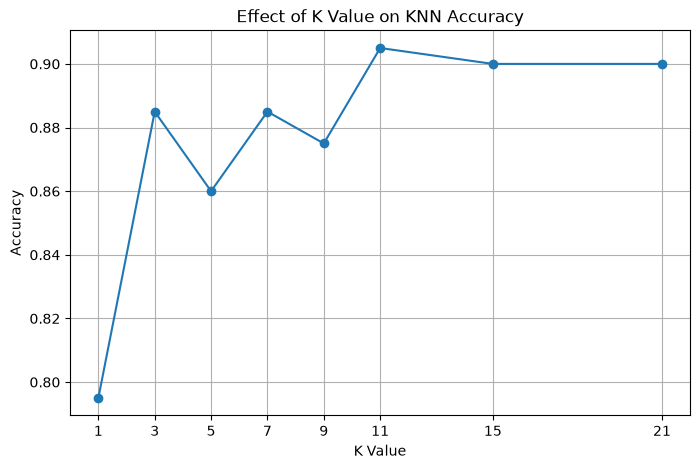

Best K: 11
Best Accuracy: 0.905
Best Precision: 0.9154929577464789
Best Recall: 0.8333333333333334
Best F1 Score: 0.87248322147651

FINAL KNN MODEL
Best K       : 11
Accuracy     : 0.905
Precision    : 0.9154929577464789
Recall       : 0.8333333333333334
F1 Score     : 0.87248322147651
Specificity  : 0.9508196721311475
AUC          : 0.9550756620428752


In [1]:
# EXERCISE – 08 (K-NEAREST NEIGHBORS)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

df = pd.read_csv("https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Heart Disease"].value_counts())

X = df.drop("Heart Disease", axis=1)

y = df["Heart Disease"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

K = 5
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train_processed,
    y_train
)

y_pred = knn.predict(
    X_test_processed
)

print("Predicted Values:")
print(y_pred[:20])

print(
    classification_report(
        y_test,
        y_pred
    )
)

k_values = [1, 3, 5, 7, 9, 11, 15, 21]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_processed,
        y_train
    )

    y_pred = knn.predict(
        X_test_processed
    )

    accuracy_values.append(
        accuracy_score(
            y_test,
            y_pred
        )
    )

    precision_values.append(
        precision_score(
            y_test,
            y_pred
        )
    )

    recall_values.append(
        recall_score(
            y_test,
            y_pred
        )
    )

    f1_values.append(
        f1_score(
            y_test,
            y_pred
        )
    )

results = pd.DataFrame({
    "K": k_values,
    "Accuracy": accuracy_values,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1 Score": f1_values
})

print(results)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")

plt.title("Effect of K Value on KNN Accuracy")

plt.xticks(k_values)

plt.grid()

plt.show()

best_index = np.argmax(f1_values)

best_k = k_values[best_index]

print("Best K:", best_k)

print(
    "Best Accuracy:",
    accuracy_values[best_index]
)

print(
    "Best Precision:",
    precision_values[best_index]
)

print(
    "Best Recall:",
    recall_values[best_index]
)

print(
    "Best F1 Score:",
    f1_values[best_index]
)

final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(
    X_train_processed,
    y_train
)

final_pred = final_knn.predict(
    X_test_processed
)

final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred
)

final_recall = recall_score(
    y_test,
    final_pred
)

final_f1 = f1_score(
    y_test,
    final_pred
)

final_cm = confusion_matrix(
    y_test,
    final_pred
)

TN, FP, FN, TP = final_cm.ravel()

final_specificity = TN / (TN + FP)

final_probability = final_knn.predict_proba(
    X_test_processed
)[:, 1]

final_auc = roc_auc_score(
    y_test,
    final_probability
)

print("\n======================================")
print("FINAL KNN MODEL")
print("======================================")

print("Best K       :", best_k)
print("Accuracy     :", final_accuracy)
print("Precision    :", final_precision)
print("Recall       :", final_recall)
print("F1 Score     :", final_f1)
print("Specificity  :", final_specificity)
print("AUC          :", final_auc)


## Result summary from the practical record
The record reports K=11 as best, with accuracy 0.905, precision 0.9155, recall 0.8333, F1 0.8725 and AUC 0.9551.

This summary is transcribed from the supplied Word record; it is not a fresh notebook execution. Run the cells to produce current outputs.

## Conclusion
Summarise findings from your execution and note limitations.

## Reproducibility
Record your Python version, dataset source/version and installed dependency versions.